# Akıllı Sınıf - İki Aşamalı AI Ajanı Eğitimi (Sensör Füzyonu)
Bu notebook'ta Radar ve CO2 verilerini birleştirerek sınıfın doluluğunu tahmin eden, ardından bu tahmin ve sıcaklığa bakarak Klima Gücüne (0-3) karar veren Uçtan Uca (End-to-End) bir model eğiteceğiz.

In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout, Concatenate
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import json

print("Kütüphaneler yüklendi. TensorFlow Versiyonu:", tf.__version__)

Kütüphaneler yüklendi. TensorFlow Versiyonu: 2.22.0-rc0


## 1. Veri Setinin Yüklenmesi ve Hazırlanması
Radar, CO2, Sıcaklık verilerini alacağız.

In [2]:
df = pd.read_csv("../2_data_collection/dataset.csv")

radar_cols = [col for col in df.columns if "Move" in col or "Stat" in col]
X = df[radar_cols + ["CO2_Egimi", "Sicaklik", "Nem"]].values

y_kisi = df["Gercek_Kisi_Sayisi"].values
y_klima = df["Hedef_Klima_Gucu"].values

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Scaler değerlerini kaydet (Arayüzde gerçek tahmin için)
with open('scaler.json', 'w') as f:
    json.dump({"min": scaler.data_min_.tolist(), "scale": scaler.scale_.tolist()}, f)

X_train, X_test, y_kisi_train, y_kisi_test, y_klima_train, y_klima_test = train_test_split(
    X_scaled, y_kisi, y_klima, test_size=0.2, random_state=42
)

print(f"Eğitim verisi: {X_train.shape[0]} satır. Test verisi: {X_test.shape[0]} satır.")

Eğitim verisi: 8000 satır. Test verisi: 2000 satır.


## 2. İki Aşamalı Yapay Zeka Mimarisinin Kurulması

In [3]:
inputs = Input(shape=(X_train.shape[1],), name="sensor_inputs")

x1 = Dense(32, activation='relu')(inputs)
x1 = Dropout(0.2)(x1)
x1 = Dense(16, activation='relu')(x1)
kisi_ciktisi = Dense(1, activation='relu', name="kisi_tahmini")(x1)

sicaklik_nem = inputs[:, -2:] 
birlestirilmis = Concatenate()([kisi_ciktisi, sicaklik_nem])

x2 = Dense(16, activation='relu')(birlestirilmis)
klima_ciktisi = Dense(4, activation='softmax', name="klima_karari")(x2)

model = Model(inputs=inputs, outputs=[kisi_ciktisi, klima_ciktisi])

model.compile(
    optimizer='adam',
    loss={'kisi_tahmini': 'mse', 'klima_karari': 'sparse_categorical_crossentropy'},
    loss_weights={'kisi_tahmini': 1.0, 'klima_karari': 2.0},
    metrics={'klima_karari': 'accuracy'}
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sensor_inputs       │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        640 │ sensor_inputs[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │        528 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ kisi_tahmini        │ (None, 1)         │         17 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 2)         │          0 │ sensor_inputs[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 3)         │          0 │ kisi_tahmini[0][… │
│ (Concatenate)       │                   │            │ get_item[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 16)        │         64 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ klima_karari        │ (None, 4)         │         68 │ dense_2[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,317 (5.14 KB)

 Trainable params: 1,317 (5.14 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Modelin Eğitilmesi

In [4]:
history = model.fit(
    X_train, 
    {'kisi_tahmini': y_kisi_train, 'klima_karari': y_klima_train},
    validation_data=(X_test, {'kisi_tahmini': y_kisi_test, 'klima_karari': y_klima_test}),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - kisi_tahmini_loss: 88.8239 - klima_karari_accuracy: 0.4179 - klima_karari_loss: 1.2713 - loss: 91.3664 - val_kisi_tahmini_loss: 5.9057 - val_klima_karari_accuracy: 0.5225 - val_klima_karari_loss: 1.0361 - val_loss: 7.9849
Epoch 2/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 595us/step - kisi_tahmini_loss: 8.9024 - klima_karari_accuracy: 0.6352 - klima_karari_loss: 0.8978 - loss: 10.6981 - val_kisi_tahmini_loss: 3.2180 - val_klima_karari_accuracy: 0.7280 - val_klima_karari_loss: 0.7684 - val_loss: 4.7587
Epoch 3/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 536us/step - kisi_tahmini_loss: 7.2625 - klima_karari_accuracy: 0.7178 - klima_karari_loss: 0.7090 - loss: 8.6805 - val_kisi_tahmini_loss: 3.0024 - val_klima_karari_accuracy: 0.7680 - val_klima_karari_loss: 0.6280 - val_loss: 4.2607
Epoch 4/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 559us/step - kisi_tahmini_loss: 7.0224 - klima_karari_accuracy: 0.7426 - klima_karari_loss: 0.6104 - loss: 8.2433 - val_kisi_tah

## 4. Eğitimi İnceleme ve TFLite Dönüşümü

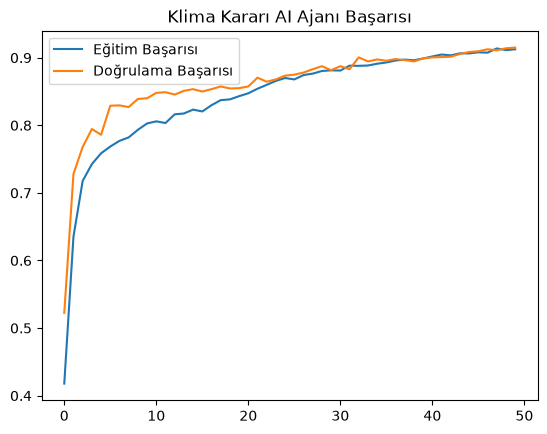

INFO:tensorflow:Assets written to: /var/folders/5l/dyy_42zd3g125dl61t_174d40000gn/T/tmpger71rdn/assets


INFO:tensorflow:Assets written to: /var/folders/5l/dyy_42zd3g125dl61t_174d40000gn/T/tmpger71rdn/assets


Saved artifact at '/var/folders/5l/dyy_42zd3g125dl61t_174d40000gn/T/tmpger71rdn'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 19), dtype=tf.float32, name='sensor_inputs')
Output Type:
  List[TensorSpec(shape=(None, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)]
Captures:
  13173790032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13170109504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13173919808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13173920768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13173920048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13173919568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13173921248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13173921008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13173921488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13173922208: TensorS

W0000 00:00:1791544955.280728 2873782 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1791544955.280863 2873782 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1791544955.281503 2873782 reader.cc:83] Reading SavedModel from: /var/folders/5l/dyy_42zd3g125dl61t_174d40000gn/T/tmpger71rdn
I0000 00:00:1791544955.281708 2873782 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1791544955.281711 2873782 reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/5l/dyy_42zd3g125dl61t_174d40000gn/T/tmpger71rdn
I0000 00:00:1791544955.283363 2873782 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1791544955.283598 2873782 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1791544955.295443 2873782 loader.cc:221] Running initialization op on SavedModel bundle at path: /var/folders/5l/dyy_42zd3g125dl61t_174d40000gn/T/tmpger71rdn
I0000 00:00:1791544955.299020 2873782 lo

In [5]:
plt.plot(history.history['klima_karari_accuracy'], label='Eğitim Başarısı')
plt.plot(history.history['val_klima_karari_accuracy'], label='Doğrulama Başarısı')
plt.title('Klima Kararı AI Ajanı Başarısı')
plt.legend()
plt.show()

# Hem Keras hem TFLite olarak kaydet (Keras'ı Streamlit kullanacak)
model.save('ai_agent.keras')

converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open('ai_agent.tflite', 'wb') as f:
    f.write(tflite_model)
    
print("Modeller kaydedildi!")